In [152]:

import os
import matplotlib.pyplot as plt 
from collections import Counter
import kagglehub
import pandas as pd

In [180]:
os.listdir('/workspace/dataset')

['Train', 'Val', 'Test', '.ipynb_checkpoints']

In [182]:
# data loading


path = kagglehub.dataset_download("ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes")

print("Path to dataset files:", path)

shutil.move(
            path,
            '/workspace/dataset'
        )

path  = '/workspace/dataset'


100%|██████████| 133M/133M [00:04<00:00, 30.4MB/s] 

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/versions/1


In [183]:

# Data exploration

data = []

for split in ["Train", "Val"]:
    split_path = os.path.join(path, split)

    print(f"-- {split.upper()} --")

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        images_path = os.path.join(class_path, "images")
        labels_path = os.path.join(class_path, "labels")

        images = os.listdir(images_path)
        labels = os.listdir(labels_path)

        print(f"\nClass: {class_name}")
        print(f"  Images: {len(images)}")
        print(f"  Labels: {len(labels)}")

        # Save the counts for the DataFrame
        data.append({
            "Split": split.capitalize(),
            "Class": class_name,
            "Images": len(images),
            "Labels": len(labels)
        })

# Create the DataFrame
df = pd.DataFrame(data)

display(df)


-- TRAIN --

Class: Glioma
  Images: 1038
  Labels: 1038

Class: Meningioma
  Images: 1305
  Labels: 1305

Class: No Tumor
  Images: 639
  Labels: 639

Class: Pituitary
  Images: 1278
  Labels: 1278
-- VAL --

Class: Glioma
  Images: 136
  Labels: 136

Class: Meningioma
  Images: 140
  Labels: 140

Class: No Tumor
  Images: 97
  Labels: 97

Class: Pituitary
  Images: 136
  Labels: 136


,Split,Class,Images,Labels
0,Train,Glioma,1038,1038
1,Train,Meningioma,1305,1305
2,Train,No Tumor,639,639
3,Train,Pituitary,1278,1278
4,Val,Glioma,136,136
5,Val,Meningioma,140,140
6,Val,No Tumor,97,97
7,Val,Pituitary,136,136


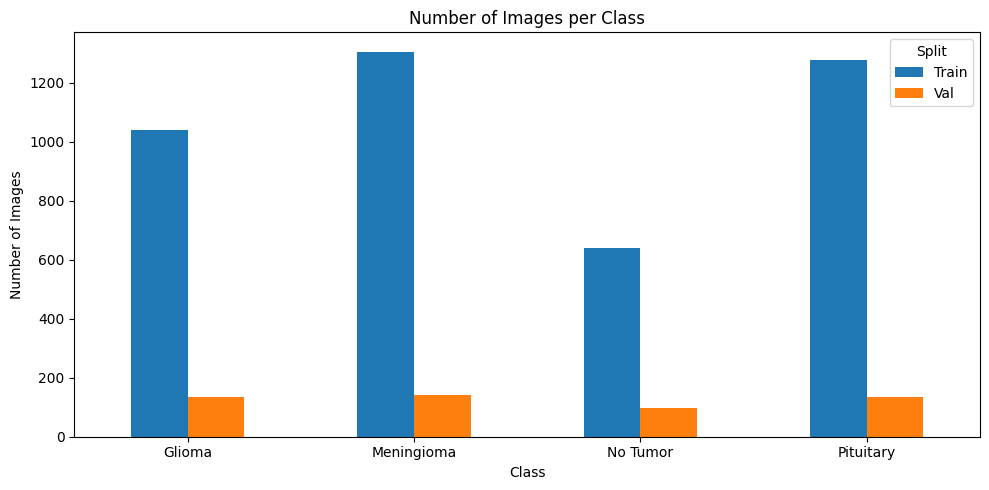

In [184]:

df.pivot(
    index="Class",
    columns="Split",
    values="Images"
).plot(kind="bar", figsize=(10, 5))

plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [156]:
# exemple of an annotation
label_file = labels[0]
label_path = os.path.join(labels_path, label_file)

with open(label_path, "r") as file:
    print(file.read())

3 0.496094 0.408203 0.062500 0.066406



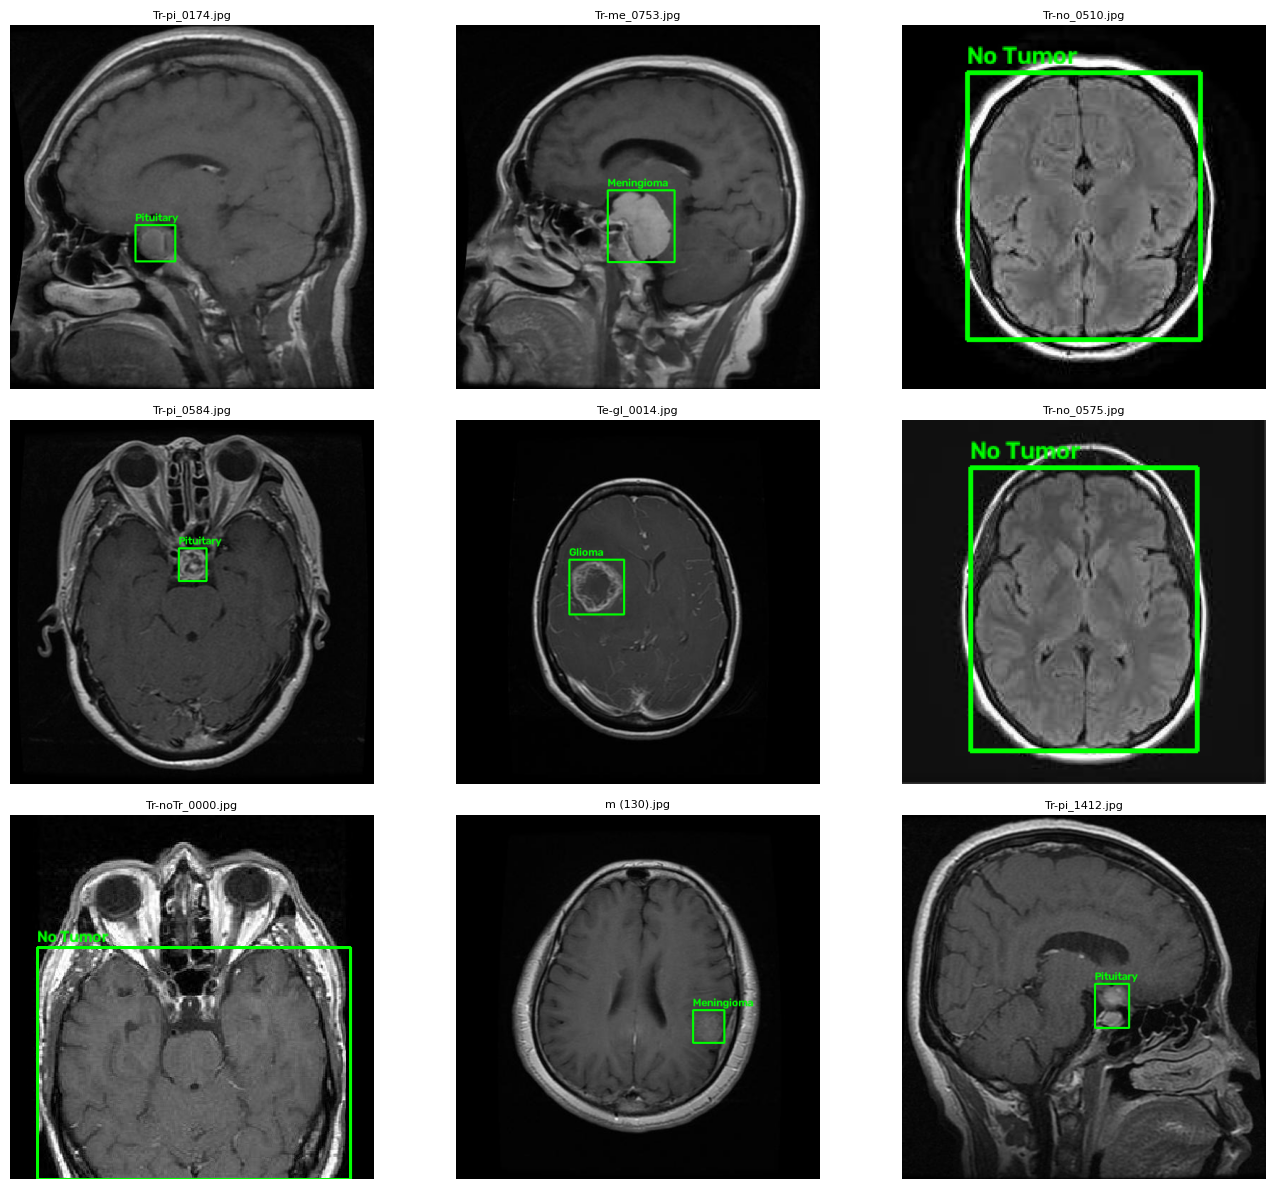

In [185]:

import os
import random
import cv2
import matplotlib.pyplot as plt

train_path = os.path.join(path, "Train")

class_names = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary"
}

# Collect images from all four classes
all_images = []

for folder in os.listdir(train_path):
    images_path = os.path.join(train_path, folder, "images")
    labels_path = os.path.join(train_path, folder, "labels")

    if os.path.isdir(images_path):
        for image_file in os.listdir(images_path):
            all_images.append((image_file, images_path, labels_path))

# Select 9 random images
random_images = random.sample(all_images, min(9, len(all_images)))

plt.figure(figsize=(14, 12))

for i, (image_file, images_path, labels_path) in enumerate(random_images):
    image_path = os.path.join(images_path, image_file)
    label_path = os.path.join(
        labels_path, os.path.splitext(image_file)[0] + ".txt"
    )

    image = cv2.imread(image_path)

    if image is None:
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    if os.path.exists(label_path):
        with open(label_path, "r") as file:
            for line in file:
                cls, x, y, w, h = map(float, line.split())

                x1 = int((x - w / 2) * width)
                y1 = int((y - h / 2) * height)
                x2 = int((x + w / 2) * width)
                y2 = int((y + h / 2) * height)

                cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

                cv2.putText(
                    image, class_names.get(int(cls), str(int(cls))),
                    (x1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2
                )

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(image_file, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [158]:

classes = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
splits = ["Train", "Val"]

# Dataset paths
train_path = os.path.join(path, "Train")
val_path = os.path.join(path, "Val")


In [159]:

def collect_issues(split_path, classes):
    issues = []

    # Check each class
    for class_name in classes:

        # Build the paths to this class's images and labels
        images_path = os.path.join(split_path, class_name, "images")
        labels_path = os.path.join(split_path, class_name, "labels")

        # If one of the folders is missing, record the problem
        if not os.path.isdir(images_path) or not os.path.isdir(labels_path):
            issues.append(f"{class_name}: missing images or labels folder")
            continue

        # Collect image filenames without their extensions
        # Example: "scan.jpg" becomes "scan"
        images = {
            os.path.splitext(f)[0]
            for f in os.listdir(images_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        }

        # Collect label filenames without the .txt extension
        labels = {
            os.path.splitext(f)[0]
            for f in os.listdir(labels_path)
            if f.endswith(".txt")
        }

        # Find images that have no matching label
        for name in images - labels:
            issues.append(f"{class_name}: image without label: {name}")

        # Find labels that have no matching image
        for name in labels - images:
            issues.append(f"{class_name}: label without image: {name}")

        # Open every label file to check its annotations
        for label_file in os.listdir(labels_path):
            if not label_file.endswith(".txt"):
                continue

            label_path = os.path.join(labels_path, label_file)

            with open(label_path, "r") as file:

                # Read each annotation line
                for line_number, line in enumerate(file, start=1):
                    if not line.strip():
                        continue

                    values = line.split()

                    try:
                        # A YOLO annotation must contain 5 values
                        if len(values) != 5:
                            raise ValueError("Expected 5 values")

                        # Read class ID and bounding-box coordinates
                        cls, x, y, w, h = map(float, values)

                        # Check that the class ID is a non-negative integer
                        if cls < 0 or not cls.is_integer():
                            raise ValueError("Invalid class ID")

                        # Coordinates and dimensions must be between 0 and 1
                        if not all(0 <= v <= 1 for v in [x, y, w, h]):
                            raise ValueError("Coordinates outside [0, 1]")

                        # Width and height must be greater than zero
                        if w <= 0 or h <= 0:
                            raise ValueError("Invalid box size")

                        

                    # save the filename and reason
                    except ValueError as error:
                        issues.append(
                            f"{class_name}/{label_file}, "
                            f"line {line_number}: {error}"
                        )

    return issues


In [160]:

train_issues = collect_issues(train_path, classes)
val_issues = collect_issues(val_path, classes)

print("Training issues:", len(train_issues))
print(*train_issues, sep="\n")

print("\nValidation issues:", len(val_issues))
print(*val_issues, sep="\n")


Training issues: 0


Validation issues: 4
No Tumor: image without label: image(61)
No Tumor: image without label: image(55)
No Tumor: label without image: image(60)
No Tumor: label without image: image(53)
